# TradeGraph (Our Hybrid Model)

## 1 : Importation of the libraries

In [1]:
# ==========================================================
# Cell 1 : Import Libraries
# ==========================================================

import os
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

from torch_geometric.nn import (
    GATConv,
    global_mean_pool
)

from torch_geometric.nn import SAGEConv

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import optuna

warnings.filterwarnings("ignore")

# ----------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------

SEED = 82

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ----------------------------------------------------------
# Device
# ----------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("Environment Information")
print("=" * 70)

print(f"PyTorch version       : {torch.__version__}")

try:
    import torch_geometric
    print(f"PyTorch Geometric     : {torch_geometric.__version__}")
except:
    pass

print(f"Optuna version        : {optuna.__version__}")
print(f"Device                : {device}")

if torch.cuda.is_available():
    print(f"GPU                    : {torch.cuda.get_device_name(0)}")

Environment Information
PyTorch version       : 2.13.0+cu130
PyTorch Geometric     : 2.8.0
Optuna version        : 4.9.0
Device                : cuda
GPU                    : NVIDIA RTX A4500


## 2: Importation of the libraries

In [2]:
# ==========================================================
# Cell 2 : Load Cleaned Dataset
# ==========================================================

file_path = "International_Trade_Semiconductor_Cleaned_Data_1995_2024.csv"

df = pd.read_csv(file_path)

# ----------------------------------------------------------
# Basic checks
# ----------------------------------------------------------

required_columns = [
    "year",
    "exporter_code",
    "exporter",
    "importer_code",
    "importer",
    "product_code",
    "product",
    "trade_value",
    "quantity",
    "HS2"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Numeric conversion
df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)

df["trade_value"] = pd.to_numeric(
    df["trade_value"],
    errors="coerce"
)

df["quantity"] = pd.to_numeric(
    df["quantity"],
    errors="coerce"
)

# Remove invalid observations
df = df.dropna(
    subset=[
        "year",
        "exporter",
        "importer",
        "trade_value"
    ]
).copy()

df = df[
    df["trade_value"] >= 0
].copy()

df["year"] = df["year"].astype(int)

df = df.sort_values(
    [
        "year",
        "exporter",
        "importer"
    ]
).reset_index(drop=True)

print("=" * 70)
print("Cleaned Dataset Loaded Successfully")
print("=" * 70)

print(f"Observations : {len(df):,}")
print(
    f"Period       : "
    f"{df['year'].min()} - {df['year'].max()}"
)

print(
    f"Countries    : "
    f"{len(set(df['exporter']) | set(df['importer']))}"
)

print("\nDataset preview:")

display(df.head())

Cleaned Dataset Loaded Successfully
Observations : 1,218,335
Period       : 1995 - 2024
Countries    : 233

Dataset preview:


,year,exporter_code,exporter,importer_code,importer,product_code,product,trade_value,quantity,HS2
0,1995,4,Afghanistan,208,Denmark,854211,"Electronic circuits: monolithic integrated, di...",2.758,0.002,85
1,1995,4,Afghanistan,246,Finland,854280,Electronic circuits and microassemblies: integ...,9.207,0.207,85
2,1995,8,Albania,12,Algeria,854130,"Electrical apparatus: thyristors, diacs and tr...",2.708,0.033,85
3,1995,8,Albania,380,Italy,854211,"Electronic circuits: monolithic integrated, di...",2.039,0.003,85
4,1995,8,Albania,484,Mexico,854211,"Electronic circuits: monolithic integrated, di...",1.000,0.002,85


## 3: Graph Preprocessing


In [3]:
# ==========================================================
# Cell 3 : Graph Preprocessing
# ==========================================================

print("=" * 70)
print("Graph Preprocessing")
print("=" * 70)

# ----------------------------------------------------------
# Aggregate product-level observations into bilateral flows
# ----------------------------------------------------------

edge_features = (
    df
    .groupby(
        [
            "year",
            "exporter",
            "importer"
        ],
        as_index=False
    )
    .agg(
        total_trade_value=(
            "trade_value",
            "sum"
        ),

        total_quantity=(
            "quantity",
            "sum"
        ),

        traded_products=(
            "product_code",
            "nunique"
        )
    )
)

# ----------------------------------------------------------
# Log-transformed target
# ----------------------------------------------------------

edge_features["log_trade_value"] = np.log1p(
    edge_features["total_trade_value"]
)

# ----------------------------------------------------------
# Global country mapping
# Same node ID across all years
# ----------------------------------------------------------

countries = sorted(
    set(edge_features["exporter"])
    |
    set(edge_features["importer"])
)

country_to_id = {
    country: idx
    for idx, country in enumerate(countries)
}

id_to_country = {
    idx: country
    for country, idx in country_to_id.items()
}

edge_features["source"] = (
    edge_features["exporter"]
    .map(country_to_id)
)

edge_features["target"] = (
    edge_features["importer"]
    .map(country_to_id)
)

print(
    f"Number of countries       : {len(countries)}"
)

print(
    f"Number of bilateral flows : {len(edge_features):,}"
)

print(
    f"Period                    : "
    f"{edge_features['year'].min()} - "
    f"{edge_features['year'].max()}"
)

display(edge_features.head())

Graph Preprocessing
Number of countries       : 233
Number of bilateral flows : 272,196
Period                    : 1995 - 2024


,year,exporter,importer,total_trade_value,total_quantity,traded_products,log_trade_value,source,target
0,1995,Afghanistan,Denmark,2.758,0.002,1,1.323887,0,62
1,1995,Afghanistan,Finland,9.207,0.207,1,2.323074,0,77
2,1995,Albania,Algeria,2.708,0.033,1,1.310493,1,2
3,1995,Albania,Italy,2.039,0.003,1,1.111529,1,105
4,1995,Albania,Mexico,1.000,0.002,1,0.693147,1,132


## 4 : Construction of Yearly Graphs



In [4]:
# ==========================================================
# Cell 4 : Construction of Yearly Graphs
# ==========================================================

print("=" * 70)
print("Construction of Yearly Trade Graphs")
print("=" * 70)

yearly_graph_data = {}

years = sorted(
    edge_features["year"].unique()
)

for year in years:

    yearly = edge_features[
        edge_features["year"] == year
    ].copy()

    edge_index = torch.tensor(
        [
            yearly["source"].values,
            yearly["target"].values
        ],
        dtype=torch.long
    )

    yearly_graph_data[year] = {
        "edge_index": edge_index,
        "dataframe": yearly
    }

    print(
        f"{year} : "
        f"{len(countries)} nodes | "
        f"{edge_index.shape[1]} directed edges"
    )

Construction of Yearly Trade Graphs
1995 : 233 nodes | 4315 directed edges
1996 : 233 nodes | 4699 directed edges
1997 : 233 nodes | 5034 directed edges
1998 : 233 nodes | 5311 directed edges
1999 : 233 nodes | 5736 directed edges
2000 : 233 nodes | 6968 directed edges
2001 : 233 nodes | 7314 directed edges
2002 : 233 nodes | 7476 directed edges
2003 : 233 nodes | 7866 directed edges
2004 : 233 nodes | 8308 directed edges
2005 : 233 nodes | 8477 directed edges
2006 : 233 nodes | 8996 directed edges
2007 : 233 nodes | 9279 directed edges
2008 : 233 nodes | 9500 directed edges
2009 : 233 nodes | 9697 directed edges
2010 : 233 nodes | 9994 directed edges
2011 : 233 nodes | 10132 directed edges
2012 : 233 nodes | 10398 directed edges
2013 : 233 nodes | 10518 directed edges
2014 : 233 nodes | 10551 directed edges
2015 : 233 nodes | 10884 directed edges
2016 : 233 nodes | 11090 directed edges
2017 : 233 nodes | 11179 directed edges
2018 : 233 nodes | 11137 directed edges
2019 : 233 nodes | 1

## 5 : Node Feature Engineering

In [5]:
# ==========================================================
# Cell 5 : Node Feature Engineering
# ==========================================================

print("=" * 70)
print("Node Feature Engineering")
print("=" * 70)

node_features_by_year = {}

NUM_NODES = len(countries)

for year in years:

    yearly = edge_features[
        edge_features["year"] == year
    ]

    features = np.zeros(
        (NUM_NODES, 6),
        dtype=np.float32
    )

    # ------------------------------------------------------
    # Degree features
    # ------------------------------------------------------

    out_degree = (
        yearly
        .groupby("source")["target"]
        .nunique()
    )

    in_degree = (
        yearly
        .groupby("target")["source"]
        .nunique()
    )

    # ------------------------------------------------------
    # Trade aggregates
    # ------------------------------------------------------

    exports = (
        yearly
        .groupby("source")["total_trade_value"]
        .sum()
    )

    imports = (
        yearly
        .groupby("target")["total_trade_value"]
        .sum()
    )

    for node in range(NUM_NODES):

        out_d = out_degree.get(node, 0)

        in_d = in_degree.get(node, 0)

        export_value = exports.get(node, 0)

        import_value = imports.get(node, 0)

        total_trade = (
            export_value
            +
            import_value
        )

        features[node] = [

            out_d,

            in_d,

            out_d + in_d,

            np.log1p(export_value),

            np.log1p(import_value),

            np.log1p(total_trade)

        ]

    node_features_by_year[year] = features

print(
    "Node features created successfully."
)

print(
    "Features:"
)

print(
    [
        "Out Degree",
        "In Degree",
        "Total Degree",
        "Log Exports",
        "Log Imports",
        "Log Total Trade"
    ]
)

Node Feature Engineering
Node features created successfully.
Features:
['Out Degree', 'In Degree', 'Total Degree', 'Log Exports', 'Log Imports', 'Log Total Trade']


## 6 : Edge Feature Engineering

In [6]:
# ==========================================================
# Cell 6 : Edge Feature Engineering
# ==========================================================

print("=" * 70)
print("Edge Feature Engineering")
print("=" * 70)

prediction_samples = {}

for year in years:

    previous_year = year - 1

    if previous_year not in years:
        continue

    current = edge_features[
        edge_features["year"] == year
    ].copy()

    previous = edge_features[
        edge_features["year"] == previous_year
    ][
        [
            "source",
            "target",
            "total_trade_value"
        ]
    ].copy()

    previous = previous.rename(
        columns={
            "total_trade_value":
            "previous_trade_value"
        }
    )

    current = current.merge(
        previous,
        on=["source", "target"],
        how="left"
    )

    current[
        "previous_trade_value"
    ] = current[
        "previous_trade_value"
    ].fillna(0)

    current[
        "log_previous_trade"
    ] = np.log1p(
        current["previous_trade_value"]
    )

    prediction_samples[year] = current

print(
    f"Prediction years : "
    f"{min(prediction_samples.keys())} - "
    f"{max(prediction_samples.keys())}"
)

display(
    prediction_samples[
        min(prediction_samples.keys())
    ].head()
)

Edge Feature Engineering
Prediction years : 1996 - 2024


,year,exporter,importer,total_trade_value,total_quantity,traded_products,log_trade_value,source,target,previous_trade_value,log_previous_trade
0,1996,Afghanistan,Finland,1.477,0.062,1,0.907048,0,77,9.207,2.323074
1,1996,Afghanistan,Slovenia,0.819,0.009,1,0.598287,0,190,0.000,0.000000
2,1996,Afghanistan,Southern African Customs Union (...1999),3.316,0.001,1,1.462329,0,195,0.000,0.000000
3,1996,Afghanistan,Switzerland,43.222,0.007,1,3.789222,0,203,0.000,0.000000
4,1996,Albania,Brazil,2.012,0.003,1,1.102604,1,31,0.000,0.000000


## 7 : PyTorch Geometric Conversion



In [7]:
# ==========================================================
# Cell 7 : PyTorch Geometric Conversion
# ==========================================================

print("=" * 70)
print("PyTorch Geometric Conversion")
print("=" * 70)

pyg_graphs = {}

for target_year in sorted(
    prediction_samples.keys()
):

    input_year = target_year - 1

    # ------------------------------------------------------
    # Node features from t-1
    # ------------------------------------------------------

    x = torch.tensor(
        node_features_by_year[input_year],
        dtype=torch.float
    )

    # ------------------------------------------------------
    # Graph structure from t-1
    # ------------------------------------------------------

    message_edge_index = (
        yearly_graph_data[input_year]
        ["edge_index"]
        .clone()
    )

    # ------------------------------------------------------
    # Prediction edges from year t
    # ------------------------------------------------------

    samples = prediction_samples[
        target_year
    ]

    target_edge_index = torch.tensor(
        [
            samples["source"].values,
            samples["target"].values
        ],
        dtype=torch.long
    )

    # Target = log(1 + trade value)
    y = torch.tensor(
        samples["log_trade_value"].values,
        dtype=torch.float
    )

    # Lagged bilateral flow
    lag_trade = torch.tensor(
        samples[
            "log_previous_trade"
        ].values,
        dtype=torch.float
    ).view(-1, 1)

    pyg_graphs[target_year] = Data(

        x=x,

        edge_index=message_edge_index,

        target_edge_index=target_edge_index,

        y=y,

        lag_trade=lag_trade

    )

print(
    f"{len(pyg_graphs)} temporal PyG graphs created."
)

example_year = sorted(
    pyg_graphs.keys()
)[0]

print(
    f"\nExample ({example_year}):"
)

print(
    pyg_graphs[example_year]
)

PyTorch Geometric Conversion
29 temporal PyG graphs created.

Example (1996):
Data(x=[233, 6], edge_index=[2, 4315], y=[4699], target_edge_index=[2, 4699], lag_trade=[4699, 1])


## 8 : Train / Validation / Test Split

In [8]:
# ==========================================================
# Cell 8 : Train / Validation / Test Split
# ==========================================================

print("=" * 70)
print("Temporal Train / Validation / Test Split")
print("=" * 70)

TRAIN_END = 2018

VAL_START = 2019
VAL_END = 2021

TEST_START = 2022
TEST_END = 2024

train_years = [
    y for y in pyg_graphs
    if y <= TRAIN_END
]

val_years = [
    y for y in pyg_graphs
    if VAL_START <= y <= VAL_END
]

test_years = [
    y for y in pyg_graphs
    if TEST_START <= y <= TEST_END
]

print(
    f"Training   : "
    f"{min(train_years)} - {max(train_years)}"
)

print(
    f"Validation : "
    f"{min(val_years)} - {max(val_years)}"
)

print(
    f"Testing    : "
    f"{min(test_years)} - {max(test_years)}"
)

# ----------------------------------------------------------
# Standardize node features
# Fit ONLY on training years
# ----------------------------------------------------------

scaler = StandardScaler()

training_features = np.vstack(
    [
        node_features_by_year[y - 1]
        for y in train_years
    ]
)

scaler.fit(training_features)

for target_year in pyg_graphs:

    input_year = target_year - 1

    scaled_features = scaler.transform(
        node_features_by_year[input_year]
    )

    pyg_graphs[target_year].x = torch.tensor(
        scaled_features,
        dtype=torch.float
    )

print(
    "\nNode features standardized using "
    "training data only."
)

Temporal Train / Validation / Test Split
Training   : 1996 - 2018
Validation : 2019 - 2021
Testing    : 2022 - 2024

Node features standardized using training data only.


## 9 : GraphSAGE Architecture



### TradeGraph Architecture

TradeGraph is a hybrid multi-branch Graph Neural Network (GNN) designed for international trade flow prediction. Instead of relying on a single graph convolution operator, the proposed architecture assumes that different message-passing mechanisms capture complementary aspects of international trade networks. Consequently, the same input graph is processed simultaneously by three independent GNN branches before their learned representations are adaptively fused into a unified embedding for trade flow prediction.

The first branch is based on **Graph Convolutional Networks (GCN)**, whose objective is to capture the **global structural organization** of the trade network. By recursively propagating information across multiple neighborhood levels, GCN learns node representations that reflect indirect relationships and long-range dependencies between countries. This enables the model to account for global supply chain effects, where trade interactions between distant economies may still influence bilateral trade flows.

The second branch employs **GraphSAGE**, which focuses on **local neighborhood aggregation**. Unlike GCN, GraphSAGE explicitly learns an aggregation function over the immediate neighbors of each node, allowing the model to capture direct bilateral trade relationships more effectively while maintaining scalability to large graphs. This branch is particularly suitable for modeling international trade because most trade flows are primarily influenced by a country's closest commercial partners.

The third branch relies on **Graph Attention Networks (GAT)** to learn **attention-weighted neighborhood representations**. Instead of treating all neighboring countries equally, GAT automatically assigns different importance scores to each trading partner according to its contribution to the prediction task. As a result, strategically important countries within the global semiconductor supply chain receive greater influence during message passing, allowing the model to emphasize the most informative trade relationships.

The embeddings generated by the GCN, GraphSAGE, and GAT branches are then concatenated and passed to a **Gated Fusion Network**. This module constitutes the core innovation of TradeGraph, as it learns adaptive fusion weights that dynamically determine the relative contribution of each branch. Rather than assuming that one aggregation mechanism is universally superior, the gating network allows the model to decide whether global structural information, local interactions, or attention-based representations should receive greater emphasis for a given trade context.

The weighted embedding is subsequently refined by a **Fusion Network**, composed of fully connected layers with ReLU activation and dropout regularization. This refinement stage transforms the fused representation into a more expressive latent space while reducing redundancy among the three branches.

To improve optimization stability and preserve the information learned by the individual branches, TradeGraph incorporates a **Residual Connection**. Specifically, the refined fused embedding is combined with the average of the three branch embeddings, facilitating gradient propagation during training and preventing the loss of useful structural information.

Finally, the resulting node embeddings are passed to a **Directed Edge Regression Decoder**. For each directed trade relationship, the decoder concatenates the embedding of the exporting country, the embedding of the importing country, and the lagged trade value from the previous year. This edge representation is processed by a multilayer perceptron (MLP) to estimate the future bilateral trade flow. By integrating global topology, local neighborhood information, attention-based partner importance, adaptive fusion, and temporal trade dynamics, TradeGraph provides a unified framework for predicting international trade flows.

In [9]:
# ==========================================================
# Part 1 : Initialization
# ==========================================================

class TradeGraphPredictor(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        embedding_dim,
        num_layers,
        heads,
        dropout
    ):

        super().__init__()

        self.dropout = dropout

        self.embedding_dim = embedding_dim

        ####################################################
        # Branch 1 : GCN
        ####################################################

        self.gcn_convs = nn.ModuleList()

        self.gcn_convs.append(

            GCNConv(

                input_dim,

                hidden_dim

            )

        )

        current_dim = hidden_dim

        for _ in range(max(0, num_layers - 2)):

            self.gcn_convs.append(

                GCNConv(

                    current_dim,

                    hidden_dim

                )

            )

        if num_layers > 1:

            self.gcn_convs.append(

                GCNConv(

                    hidden_dim,

                    embedding_dim

                )

            )

        else:

            self.gcn_convs[0] = GCNConv(

                input_dim,

                embedding_dim

            )

        ####################################################
        # Branch 2 : GraphSAGE
        ####################################################

        self.sage_convs = nn.ModuleList()

        self.sage_convs.append(

            SAGEConv(

                input_dim,

                hidden_dim

            )

        )

        current_dim = hidden_dim

        for _ in range(max(0, num_layers - 2)):

            self.sage_convs.append(

                SAGEConv(

                    current_dim,

                    hidden_dim

                )

            )

        if num_layers > 1:

            self.sage_convs.append(

                SAGEConv(

                    hidden_dim,

                    embedding_dim

                )

            )

        else:

            self.sage_convs[0] = SAGEConv(

                input_dim,

                embedding_dim

            )

        ####################################################
        # Branch 3 : GAT
        ####################################################

        self.gat_convs = nn.ModuleList()

        self.gat_convs.append(

            GATConv(

                input_dim,

                hidden_dim,

                heads=heads,

                concat=True,

                dropout=dropout

            )

        )

        current_dim = hidden_dim * heads

        for _ in range(max(0, num_layers - 2)):

            self.gat_convs.append(

                GATConv(

                    current_dim,

                    hidden_dim,

                    heads=heads,

                    concat=True,

                    dropout=dropout

                )

            )

            current_dim = hidden_dim * heads

        if num_layers > 1:

            self.gat_convs.append(

                GATConv(

                    current_dim,

                    embedding_dim,

                    heads=1,

                    concat=False,

                    dropout=dropout

                )

            )

        else:

            self.gat_convs[0] = GATConv(

                input_dim,

                embedding_dim,

                heads=1,

                concat=False,

                dropout=dropout

            )

        ####################################################
        # Gated Fusion Network
        ####################################################

        # Learn the importance of each branch

        self.gate_network = nn.Sequential(

            nn.Linear(

                embedding_dim * 3,

                embedding_dim

            ),

            nn.ReLU(),

            nn.Dropout(

                dropout

            ),

            nn.Linear(

                embedding_dim,

                3

            ),

            nn.Softmax(dim=1)

        )

        ####################################################
        # Fusion refinement
        ####################################################

        self.fusion_network = nn.Sequential(

            nn.Linear(

                embedding_dim,

                hidden_dim

            ),

            nn.ReLU(),

            nn.Dropout(

                dropout

            ),

            nn.Linear(

                hidden_dim,

                embedding_dim

            )

        )

        ####################################################
        # Directed Edge Regression Decoder
        ####################################################

        self.edge_decoder = nn.Sequential(

            nn.Linear(

                embedding_dim * 2 + 1,

                hidden_dim

            ),

            nn.ReLU(),

            nn.Dropout(

                dropout

            ),

            nn.Linear(

                hidden_dim,

                hidden_dim // 2

            ),

            nn.ReLU(),

            nn.Linear(

                hidden_dim // 2,

                1

            )

        )

    ####################################################
    # Part 2 : Branch 1 - GCN Encoder
    ####################################################

    def encode_gcn(
        self,
        x,
        edge_index
    ):

        for i, conv in enumerate(self.gcn_convs):

            x = conv(
                x,
                edge_index
            )

            if i != len(self.gcn_convs) - 1:

                x = F.relu(x)

                x = F.dropout(
                    x,
                    p=self.dropout,
                    training=self.training
                )

        return x


    ####################################################
    # Branch 2 : GraphSAGE Encoder
    ####################################################

    def encode_sage(
        self,
        x,
        edge_index
    ):

        for i, conv in enumerate(self.sage_convs):

            x = conv(
                x,
                edge_index
            )

            if i != len(self.sage_convs) - 1:

                x = F.relu(x)

                x = F.dropout(
                    x,
                    p=self.dropout,
                    training=self.training
                )

        return x


    ####################################################
    # Branch 3 : GAT Encoder
    ####################################################

    def encode_gat(
        self,
        x,
        edge_index
    ):

        for i, conv in enumerate(self.gat_convs):

            x = conv(
                x,
                edge_index
            )

            if i != len(self.gat_convs) - 1:

                x = F.elu(x)

                x = F.dropout(
                    x,
                    p=self.dropout,
                    training=self.training
                )

        return x
        
    ####################################################
    # Part 3 : fuse() + decode() : Gated Fusion
    ####################################################

    def fuse(
        self,
        z_gcn,
        z_sage,
        z_gat
    ):

        # -----------------------------------------------
        # Concatenate the three representations
        # -----------------------------------------------

        z_concat = torch.cat(

            [

                z_gcn,

                z_sage,

                z_gat

            ],

            dim=1

        )

        # -----------------------------------------------
        # Learn branch importance
        # -----------------------------------------------

        gate_weights = self.gate_network(

            z_concat

        )

        alpha = gate_weights[:, 0].unsqueeze(1)

        beta = gate_weights[:, 1].unsqueeze(1)

        gamma = gate_weights[:, 2].unsqueeze(1)

        # -----------------------------------------------
        # Weighted fusion
        # -----------------------------------------------

        z_fused = (

            alpha * z_gcn +

            beta * z_sage +

            gamma * z_gat

        )

        # -----------------------------------------------
        # Fusion refinement
        # -----------------------------------------------

        z_final = self.fusion_network(

            z_fused

        )

        return z_final


    ####################################################
    # Directed Edge Regression Decoder
    ####################################################

    def decode(
        self,
        z,
        target_edge_index,
        lag_trade
    ):

        source = target_edge_index[0]

        target = target_edge_index[1]

        edge_representation = torch.cat(

            [

                z[source],

                z[target],

                lag_trade

            ],

            dim=1

        )

        prediction = self.edge_decoder(

            edge_representation

        )

        return prediction.squeeze(-1)
        
    ####################################################
    # Part 4 : Forward
    ####################################################

    def forward(
        self,
        data
    ):

        # ------------------------------------------------
        # Branch 1 : Global Structural Representation
        # (GCN)
        # ------------------------------------------------

        z_gcn = self.encode_gcn(

            data.x,

            data.edge_index

        )

        # ------------------------------------------------
        # Branch 2 : Local Neighborhood Representation
        # (GraphSAGE)
        # ------------------------------------------------

        z_sage = self.encode_sage(

            data.x,

            data.edge_index

        )

        # ------------------------------------------------
        # Branch 3 : Partner Importance Representation
        # (GAT)
        # ------------------------------------------------

        z_gat = self.encode_gat(

            data.x,

            data.edge_index

        )

        # ------------------------------------------------
        # Gated Fusion
        # ------------------------------------------------

        z = self.fuse(

            z_gcn,

            z_sage,

            z_gat

        )

        # ------------------------------------------------
        # Residual Connection
        # Improves optimization stability
        # ------------------------------------------------

        z = z + (

            z_gcn +

            z_sage +

            z_gat

        ) / 3.0

        # ------------------------------------------------
        # Directed Edge Regression
        # ------------------------------------------------

        prediction = self.decode(

            z,

            data.target_edge_index,

            data.lag_trade

        )

        return prediction


# ==========================================================
# TradeGraph Architecture Successfully Defined
# ==========================================================

print(
    "TradeGraphPredictor architecture defined successfully."
)

print(
    "Branches : GCN + GraphSAGE + GAT"
)

print(
    "Fusion : Gated Attention Fusion (Softmax)"
)

print(
    "Decoder : Directed Edge Regression Decoder"
)

print(
    "Output : Trade Flow Prediction"
)
    

TradeGraphPredictor architecture defined successfully.
Branches : GCN + GraphSAGE + GAT
Fusion : Gated Attention Fusion (Softmax)
Decoder : Directed Edge Regression Decoder
Output : Trade Flow Prediction


## 10 : Hyperparameter Optimization with Optuna

In [10]:
# ==========================================================
# Part 1 (Cell 10) : Hyperparameter Optimization (TradeGraph)
# ==========================================================

print("=" * 70)
print("TradeGraph Hyperparameter Optimization with Optuna")
print("=" * 70)


# ==========================================================
# Training Function
# ==========================================================

def train_one_epoch(
    model,
    optimizer,
    years_subset
):

    model.train()

    total_loss = 0.0

    for year in years_subset:

        data = pyg_graphs[year].to(device)

        optimizer.zero_grad()

        predictions = model(data)

        loss = F.mse_loss(
            predictions,
            data.y
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(years_subset)


# ==========================================================
# Validation Function
# ==========================================================

@torch.no_grad()
def evaluate_log_rmse(
    model,
    years_subset
):

    model.eval()

    predictions_all = []

    targets_all = []

    for year in years_subset:

        data = pyg_graphs[year].to(device)

        predictions = model(data)

        predictions_all.append(
            predictions.cpu().numpy()
        )

        targets_all.append(
            data.y.cpu().numpy()
        )

    predictions_all = np.concatenate(
        predictions_all
    )

    targets_all = np.concatenate(
        targets_all
    )

    rmse = np.sqrt(

        mean_squared_error(

            targets_all,

            predictions_all

        )

    )

    return rmse


# ==========================================================
# Optuna Objective Function
# ==========================================================

def objective(trial):

    # ------------------------------------------------------
    # Reproducibility
    # ------------------------------------------------------

    random.seed(SEED)

    np.random.seed(SEED)

    torch.manual_seed(SEED)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    if torch.cuda.is_available():

        torch.cuda.manual_seed(SEED)

        torch.cuda.manual_seed_all(SEED)

    # ------------------------------------------------------
    # Hyperparameter Search Space
    # ------------------------------------------------------

    hidden_dim = trial.suggest_categorical(

        "hidden_dim",

        [64, 128, 256]

    )

    embedding_dim = trial.suggest_categorical(

        "embedding_dim",

        [32, 64, 128]

    )

    num_layers = trial.suggest_int(

        "num_layers",

        2,

        4

    )

    heads = trial.suggest_categorical(

        "heads",

        [2, 4, 8]

    )

    dropout = trial.suggest_float(

        "dropout",

        0.0,

        0.5

    )

    learning_rate = trial.suggest_float(

        "learning_rate",

        1e-4,

        5e-3,

        log=True

    )

    weight_decay = trial.suggest_float(

        "weight_decay",

        1e-7,

        1e-3,

        log=True

    )

    # ------------------------------------------------------
    # Build TradeGraph Model
    # ------------------------------------------------------

    model = TradeGraphPredictor(

        input_dim=
            pyg_graphs[
                train_years[0]
            ].x.shape[1],

        hidden_dim=hidden_dim,

        embedding_dim=embedding_dim,

        num_layers=num_layers,

        heads=heads,

        dropout=dropout

    ).to(device)

    # ------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------

    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=learning_rate,

        weight_decay=weight_decay

    )

    # ------------------------------------------------------
    # Early Stopping
    # ------------------------------------------------------

    best_val_rmse = float("inf")

    patience = 20

    patience_counter = 0

    MAX_OPTUNA_EPOCHS = 100

    # ------------------------------------------------------
    # Optimization Loop
    # ------------------------------------------------------

    for epoch in range(MAX_OPTUNA_EPOCHS):

        train_one_epoch(

            model,

            optimizer,

            train_years

        )

        val_rmse = evaluate_log_rmse(

            model,

            val_years

        )

        trial.report(

            val_rmse,

            epoch

        )

        if trial.should_prune():

            raise optuna.TrialPruned()

        if val_rmse < best_val_rmse:

            best_val_rmse = val_rmse

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:

            break

    return best_val_rmse

# ==========================================================
# Optuna Study
# ==========================================================

sampler = optuna.samplers.TPESampler(

    seed=SEED

)

pruner = optuna.pruners.MedianPruner(

    n_startup_trials=5,

    n_warmup_steps=10

)

study = optuna.create_study(

    direction="minimize",

    sampler=sampler,

    pruner=pruner,

    study_name="TradeGraph_Optimization"

)


# ==========================================================
# Run Hyperparameter Optimization
# ==========================================================

study.optimize(

    objective,

    n_trials=100,

    show_progress_bar=True

)


# ==========================================================
# Best Hyperparameters
# ==========================================================

best_params = study.best_params

print("\n")

print("=" * 70)

print("BEST HYPERPARAMETERS")

print("=" * 70)

for parameter, value in best_params.items():

    print(

        f"{parameter:<20}: {value}"

    )


print("\n")

print("=" * 70)

print("BEST VALIDATION PERFORMANCE")

print("=" * 70)

print(

    f"Validation RMSE (log scale): "

    f"{study.best_value:.6f}"

)


# ==========================================================
# Summary
# ==========================================================

print("\n")

print("=" * 70)

print("TradeGraph Hyperparameter Optimization Completed")

print("=" * 70)

print(

    "Best configuration successfully identified."

)

print(

    "Ready for final model training."

)

[I 2026-07-28 18:24:24,627] A new study created in memory with name: TradeGraph_Optimization


TradeGraph Hyperparameter Optimization with Optuna


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-07-28 18:25:37,685] Trial 0 finished with value: 1.3412879705429077 and parameters: {'hidden_dim': 128, 'embedding_dim': 128, 'num_layers': 4, 'heads': 2, 'dropout': 0.3075073084338909, 'learning_rate': 0.0010173425845152234, 'weight_decay': 3.7942153282661795e-05}. Best is trial 0 with value: 1.3412879705429077.
[I 2026-07-28 18:26:29,558] Trial 1 finished with value: 1.3376270532608032 and parameters: {'hidden_dim': 64, 'embedding_dim': 32, 'num_layers': 2, 'heads': 2, 'dropout': 0.17205396028793452, 'learning_rate': 0.000419185104873727, 'weight_decay': 1.1155088463766091e-07}. Best is trial 1 with value: 1.3376270532608032.
[I 2026-07-28 18:27:41,230] Trial 2 finished with value: 1.3366061449050903 and parameters: {'hidden_dim': 256, 'embedding_dim': 128, 'num_layers': 4, 'heads': 2, 'dropout': 0.08229930233464577, 'learning_rate': 0.003911912025424786, 'weight_decay': 0.0008980558745569912}. Best is trial 2 with value: 1.3366061449050903.
[I 2026-07-28 18:28:33,052] Trial 

## 11 : Final Model Training

In [11]:
# ==========================================================
# Cell 11 : Final TradeGraph Model Training
# ==========================================================

print("=" * 70)
print("Final TradeGraph Model Training")
print("=" * 70)

# ----------------------------------------------------------
# Reset random seeds before final model training
# ----------------------------------------------------------

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed(SEED)

    torch.cuda.manual_seed_all(SEED)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


# ----------------------------------------------------------
# Initialize Best TradeGraph Model
# ----------------------------------------------------------

best_model = TradeGraphPredictor(

    input_dim=
        pyg_graphs[
            train_years[0]
        ].x.shape[1],

    hidden_dim=
        best_params["hidden_dim"],

    embedding_dim=
        best_params["embedding_dim"],

    num_layers=
        best_params["num_layers"],

    heads=
        best_params["heads"],

    dropout=
        best_params["dropout"]

).to(device)


# ----------------------------------------------------------
# Optimizer
# ----------------------------------------------------------

optimizer = torch.optim.Adam(

    best_model.parameters(),

    lr=
        best_params["learning_rate"],

    weight_decay=
        best_params["weight_decay"]

)


# ----------------------------------------------------------
# Training Configuration
# ----------------------------------------------------------

MAX_EPOCHS = 500

PATIENCE = 50

best_val_rmse = float("inf")

best_model_state = None

patience_counter = 0

best_epoch = 0

train_rmse_history = []

val_rmse_history = []


# ----------------------------------------------------------
# Final Training Loop
# ----------------------------------------------------------

for epoch in range(

    1,

    MAX_EPOCHS + 1

):

    # ------------------------------------------------------
    # One Training Epoch
    # ------------------------------------------------------

    train_mse = train_one_epoch(

        best_model,

        optimizer,

        train_years

    )

    train_rmse = np.sqrt(

        train_mse

    )

    # ------------------------------------------------------
    # Validation
    # ------------------------------------------------------

    val_rmse = evaluate_log_rmse(

        best_model,

        val_years

    )

    # ------------------------------------------------------
    # Save Learning Curves
    # ------------------------------------------------------

    train_rmse_history.append(

        train_rmse

    )

    val_rmse_history.append(

        val_rmse

    )

    # ------------------------------------------------------
    # Check Best Model
    # ------------------------------------------------------

    if val_rmse < best_val_rmse:

        best_val_rmse = val_rmse

        best_epoch = epoch

        best_model_state = copy.deepcopy(

            best_model.state_dict()

        )

        patience_counter = 0

    else:

        patience_counter += 1
    
    # ------------------------------------------------------
    # Display Progress
    # ------------------------------------------------------

    if epoch % 25 == 0:

        print(

            f"Epoch {epoch:4d} | "

            f"Train RMSE: "

            f"{train_rmse:.6f} | "

            f"Validation RMSE: "

            f"{val_rmse:.6f}"

        )

    # ------------------------------------------------------
    # Early Stopping
    # ------------------------------------------------------

    if patience_counter >= PATIENCE:

        print(

            f"\nEarly stopping triggered "

            f"at epoch {epoch}."

        )

        break


# ----------------------------------------------------------
# Restore Best Model
# ----------------------------------------------------------

best_model.load_state_dict(

    best_model_state

)


print("\n")

print("=" * 70)

print("TradeGraph Training Completed")

print("=" * 70)

print(

    f"Best Epoch           : {best_epoch}"

)

print(

    f"Best Validation RMSE : "

    f"{best_val_rmse:.6f}"

)


# ----------------------------------------------------------
# Save Best Model
# ----------------------------------------------------------

torch.save(

    best_model.state_dict(),

    "best_tradegraph_model.pth"

)


print(

    "\nBest model saved as : "

    "best_tradegraph_model.pth"

)


# ----------------------------------------------------------
# Training Summary
# ----------------------------------------------------------

print("\n")

print("=" * 70)

print("TradeGraph Final Model Ready")

print("=" * 70)

print(

    "The optimized TradeGraph model "

    "is now ready for testing."

)

Final TradeGraph Model Training
Epoch   25 | Train RMSE: 1.373803 | Validation RMSE: 1.331098
Epoch   50 | Train RMSE: 1.372899 | Validation RMSE: 1.331254
Epoch   75 | Train RMSE: 1.366091 | Validation RMSE: 1.328909
Epoch  100 | Train RMSE: 1.372946 | Validation RMSE: 1.331256
Epoch  125 | Train RMSE: 1.350372 | Validation RMSE: 1.325072
Epoch  150 | Train RMSE: 1.340257 | Validation RMSE: 1.327006
Epoch  175 | Train RMSE: 1.338631 | Validation RMSE: 1.323729

Early stopping triggered at epoch 191.


TradeGraph Training Completed
Best Epoch           : 141
Best Validation RMSE : 1.322115

Best model saved as : best_tradegraph_model.pth


TradeGraph Final Model Ready
The optimized TradeGraph model is now ready for testing.


## 12 : Performance Evaluation

TradeGraph Performance Evaluation
Seed =  82


TRAIN / VALIDATION / TEST PERFORMANCE


,Dataset,MSE (Billion USD²),RMSE (Billion USD),MAE (Billion USD),R²
0,Training,0.0546,0.2337,0.0138,0.8654
1,Validation,0.0843,0.2904,0.0178,0.9471
2,Test,0.1035,0.3217,0.0233,0.9539




BEST HYPERPARAMETERS
hidden_dim          : 256
embedding_dim       : 32
num_layers          : 2
heads               : 8
dropout             : 0.020026631197368593
learning_rate       : 0.0015639443017267521
weight_decay        : 6.9049606227594705e-06
best_epoch          : 141


GLOBAL TEST PERFORMANCE (2022–2024)


,Metric,Value,Unit
0,MSE,0.1035,Billion USD²
1,RMSE,0.3217,Billion USD
2,MAE,0.0233,Billion USD
3,R²,0.9539,Dimensionless




PERFORMANCE BY TEST YEAR


,Year,MSE (Billion USD²),RMSE (Billion USD),MAE (Billion USD),R²
0,2022,0.0760,0.2757,0.0209,0.9687
1,2023,0.1219,0.3492,0.0249,0.9333
2,2024,0.1130,0.3361,0.0241,0.9546


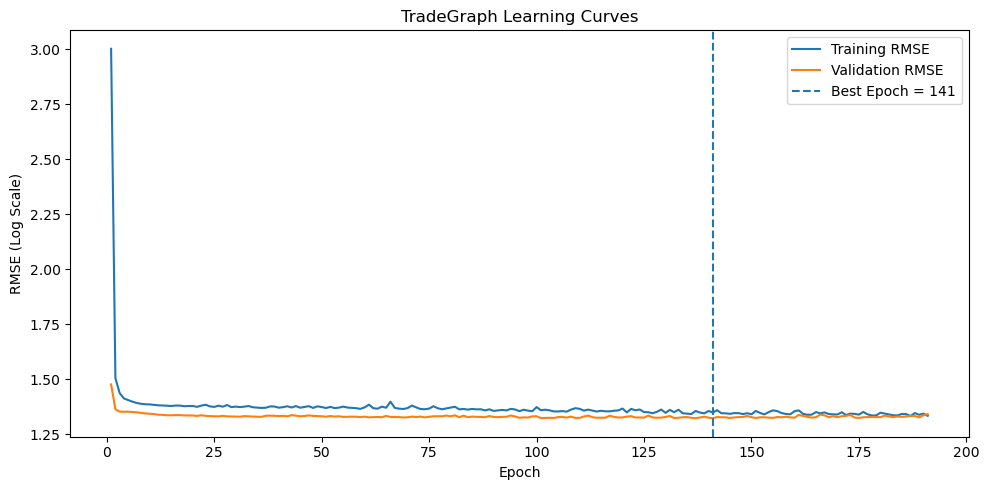

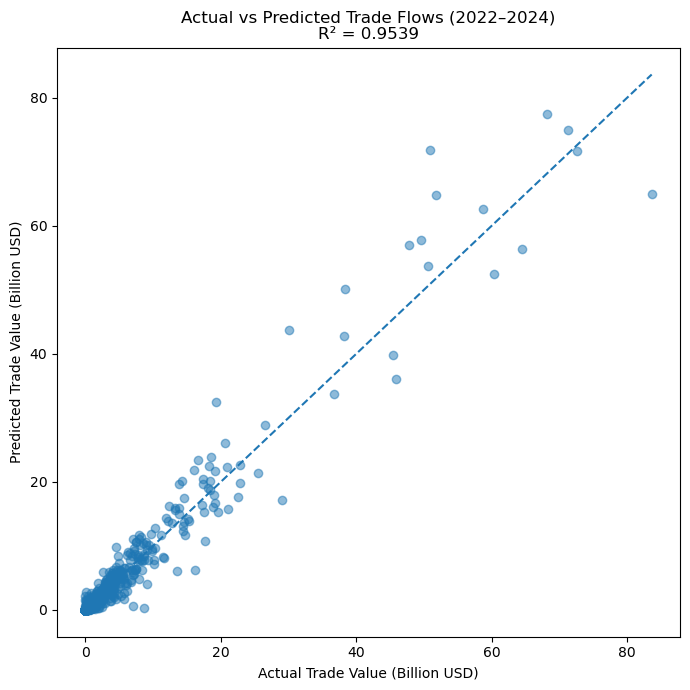

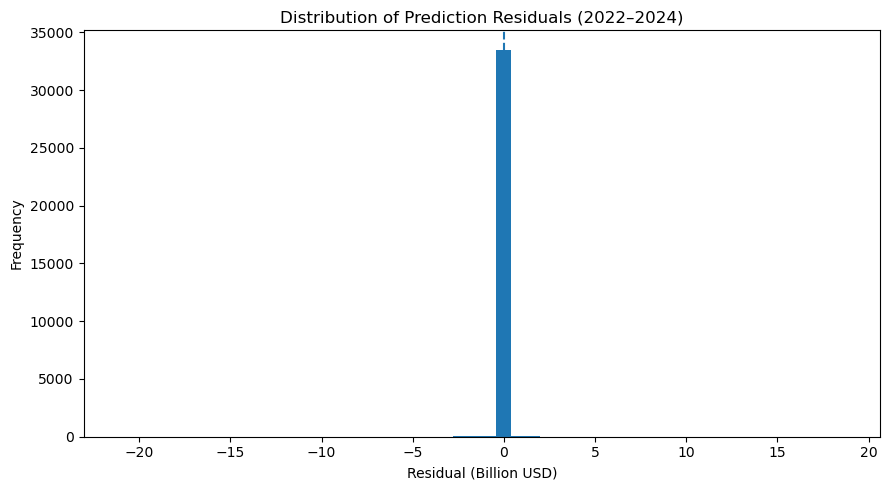



TOP 20 LARGEST ACTUAL TRADE FLOWS (TEST PERIOD 2022–2024)


,Year,Exporter,Importer,Actual Trade (Billion USD),Predicted Trade (Billion USD),Absolute Error (Billion USD),Relative Error (%)
0,2024,China,"China, Hong Kong SAR",83.6043,64.9615,18.6428,22.2989
1,2023,China,"China, Hong Kong SAR",72.5261,71.6060,0.9201,1.2687
2,2022,China,"China, Hong Kong SAR",71.2368,74.9410,3.7042,5.1998
3,2022,Rep. of Korea,China,68.1600,77.4046,9.2446,13.5630
4,2024,Rep. of Korea,China,64.4104,56.4229,7.9875,12.4010
5,2022,"Other Asia, nes",China,60.3728,52.4117,7.9611,13.1866
6,2022,"Other Asia, nes","China, Hong Kong SAR",58.6591,62.6290,3.9700,6.7679
7,2023,"Other Asia, nes","China, Hong Kong SAR",51.7956,64.8194,13.0238,25.1447
8,2023,Rep. of Korea,China,50.8122,71.8729,21.0607,41.4482
9,2024,"Other Asia, nes",China,50.5928,53.6504,3.0577,6.0437




TOP 20 LARGEST PREDICTED TRADE FLOWS (TEST PERIOD 2022–2024)


,Year,Exporter,Importer,Actual Trade (Billion USD),Predicted Trade (Billion USD),Absolute Error (Billion USD),Relative Error (%)
0,2022,Rep. of Korea,China,68.1600,77.4046,9.2446,13.5630
1,2022,China,"China, Hong Kong SAR",71.2368,74.9410,3.7042,5.1998
2,2023,Rep. of Korea,China,50.8122,71.8729,21.0607,41.4482
3,2023,China,"China, Hong Kong SAR",72.5261,71.6060,0.9201,1.2687
4,2024,China,"China, Hong Kong SAR",83.6043,64.9615,18.6428,22.2989
5,2023,"Other Asia, nes","China, Hong Kong SAR",51.7956,64.8194,13.0238,25.1447
6,2022,"Other Asia, nes","China, Hong Kong SAR",58.6591,62.6290,3.9700,6.7679
7,2023,"Other Asia, nes",China,49.5887,57.6898,8.1010,16.3364
8,2024,"Other Asia, nes","China, Hong Kong SAR",47.7702,57.0171,9.2469,19.3570
9,2024,Rep. of Korea,China,64.4104,56.4229,7.9875,12.4010




SAMPLE TEST PREDICTIONS


,Year,Exporter,Importer,Actual Trade (Billion USD),Predicted Trade (Billion USD),Absolute Error (Billion USD),Relative Error (%)
0,2022,Afghanistan,Canada,0.0000,0.0,0.0000,46.1702
1,2022,Afghanistan,China,0.0000,0.0,0.0000,39.9300
2,2022,Afghanistan,Guatemala,0.0000,0.0,0.0000,482.1211
3,2022,Afghanistan,Ireland,0.0000,0.0,0.0000,1116.0563
4,2022,Afghanistan,Japan,0.0001,0.0,0.0000,56.7806
5,2022,Afghanistan,Malaysia,0.0004,0.0,0.0004,98.5569
6,2022,Afghanistan,Poland,0.0000,0.0,0.0000,22.5983
7,2022,Afghanistan,Rep. of Korea,0.0000,0.0,0.0000,4427.7208
8,2022,Afghanistan,Singapore,0.0000,0.0,0.0000,60.0892
9,2022,Afghanistan,Slovakia,0.0000,0.0,0.0000,49.4300


In [12]:
# ==========================================================
# Cell 12 : Performance Evaluation
# ==========================================================

print("=" * 70)
print("TradeGraph Performance Evaluation")
print("Seed = ",SEED)
print("=" * 70)


@torch.no_grad()
def predict_years(
    model,
    years_subset
):

    model.eval()

    results = []

    for year in years_subset:

        data = pyg_graphs[year].to(
            device
        )

        pred_log = model(
            data
        ).cpu().numpy()

        true_log = (
            data.y
            .cpu()
            .numpy()
        )

        # --------------------------------------------------
        # Back-transform from log1p
        # --------------------------------------------------

        pred_original = np.expm1(
            pred_log
        )

        true_original = np.expm1(
            true_log
        )

        # Negative predictions are not economically valid
        pred_original = np.clip(
            pred_original,
            0,
            None
        )

        samples = prediction_samples[
            year
        ].reset_index(drop=True)

        for i in range(
            len(samples)
        ):

            results.append({

                "Year":
                    year,

                "Exporter":
                    samples.loc[
                        i,
                        "exporter"
                    ],

                "Importer":
                    samples.loc[
                        i,
                        "importer"
                    ],

                "Actual_Trade":
                    true_original[i],

                "Predicted_Trade":
                    pred_original[i]

            })

    return pd.DataFrame(
        results
    )


# ==========================================================
# Generate Train / Validation / Test Predictions
# ==========================================================

train_predictions = predict_years(
    best_model,
    train_years
)

val_predictions = predict_years(
    best_model,
    val_years
)

test_predictions = predict_years(
    best_model,
    test_years
)


# ==========================================================
# Convert BACI Thousand USD -> Billion USD
# ==========================================================

for predictions_df in [
    train_predictions,
    val_predictions,
    test_predictions
]:

    predictions_df[
        "Actual Trade (Billion USD)"
    ] = (
        predictions_df[
            "Actual_Trade"
        ]
        / 1_000_000
    )

    predictions_df[
        "Predicted Trade (Billion USD)"
    ] = (
        predictions_df[
            "Predicted_Trade"
        ]
        / 1_000_000
    )


# ==========================================================
# Function for Performance Metrics
# ==========================================================

def calculate_metrics(
    predictions_df
):

    true_values = predictions_df[
        "Actual_Trade"
    ].values

    predicted_values = predictions_df[
        "Predicted_Trade"
    ].values

    mse_value = mean_squared_error(
        true_values,
        predicted_values
    )

    rmse_value = np.sqrt(
        mse_value
    )

    mae_value = mean_absolute_error(
        true_values,
        predicted_values
    )

    r2_value = r2_score(
        true_values,
        predicted_values
    )

    return {

        "MSE (Billion USD²)":
            mse_value
            / (1_000_000 ** 2),

        "RMSE (Billion USD)":
            rmse_value
            / 1_000_000,

        "MAE (Billion USD)":
            mae_value
            / 1_000_000,

        "R²":
            r2_value

    }


# ==========================================================
# Train / Validation / Test Performance
# ==========================================================

generalization_metrics = pd.DataFrame([

    {
        "Dataset": "Training",
        **calculate_metrics(
            train_predictions
        )
    },

    {
        "Dataset": "Validation",
        **calculate_metrics(
            val_predictions
        )
    },

    {
        "Dataset": "Test",
        **calculate_metrics(
            test_predictions
        )
    }

]).round(4)


print("\n")

print("=" * 70)
print("TRAIN / VALIDATION / TEST PERFORMANCE")
print("=" * 70)

display(
    generalization_metrics
)


# ==========================================================
# Global Test Performance
# ==========================================================

global_test_metrics = calculate_metrics(
    test_predictions
)

performance_metrics = pd.DataFrame({

    "Metric": [
        "MSE",
        "RMSE",
        "MAE",
        "R²"
    ],

    "Value": [

        global_test_metrics[
            "MSE (Billion USD²)"
        ],

        global_test_metrics[
            "RMSE (Billion USD)"
        ],

        global_test_metrics[
            "MAE (Billion USD)"
        ],

        global_test_metrics[
            "R²"
        ]

    ],

    "Unit": [

        "Billion USD²",

        "Billion USD",

        "Billion USD",

        "Dimensionless"

    ]

}).round(4)


# ==========================================================
# Best Hyperparameters
# ==========================================================

print("\n")

print("=" * 70)
print("BEST HYPERPARAMETERS")
print("=" * 70)

for parameter, value in best_params.items():

    print(
        f"{parameter:<20}: {value}"
    )

print(
    f"{'best_epoch':<20}: "
    f"{best_epoch}"
)


# ==========================================================
# Global Test Performance
# ==========================================================

print("\n")

print("=" * 70)
print("GLOBAL TEST PERFORMANCE (2022–2024)")
print("=" * 70)

display(
    performance_metrics
)


# ==========================================================
# Performance by Test Year
# ==========================================================

yearly_metrics = []

for year in test_years:

    yearly_results = test_predictions[
        test_predictions["Year"] == year
    ]

    metrics_year = calculate_metrics(
        yearly_results
    )

    yearly_metrics.append({

        "Year":
            year,

        **metrics_year

    })


yearly_metrics = pd.DataFrame(
    yearly_metrics
).round(4)


print("\n")

print("=" * 70)
print("PERFORMANCE BY TEST YEAR")
print("=" * 70)

display(
    yearly_metrics
)


# ==========================================================
# Learning Curves
# ==========================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(
        1,
        len(train_rmse_history) + 1
    ),
    train_rmse_history,
    label="Training RMSE"
)

plt.plot(
    range(
        1,
        len(val_rmse_history) + 1
    ),
    val_rmse_history,
    label="Validation RMSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.title(
    "TradeGraph Learning Curves"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "RMSE (Log Scale)"
)

plt.legend()

plt.grid(False)

plt.tight_layout()

plt.show()


# ==========================================================
# Actual vs Predicted
# IMPORTANT:
# Use the complete 2022–2024 test set
# ==========================================================

y_true_test = test_predictions[
    "Actual Trade (Billion USD)"
].values

y_pred_test = test_predictions[
    "Predicted Trade (Billion USD)"
].values


plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    y_true_test,
    y_pred_test,
    alpha=0.5
)

minimum = min(
    y_true_test.min(),
    y_pred_test.min()
)

maximum = max(
    y_true_test.max(),
    y_pred_test.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted Trade Flows (2022–2024)\n"
    f"R² = {global_test_metrics['R²']:.4f}"
)

plt.xlabel(
    "Actual Trade Value (Billion USD)"
)

plt.ylabel(
    "Predicted Trade Value (Billion USD)"
)

plt.grid(False)

plt.tight_layout()

plt.show()


# ==========================================================
# Residual Distribution
# ==========================================================

residuals = (
    y_true_test
    -
    y_pred_test
)

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    residuals,
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Distribution of Prediction Residuals (2022–2024)"
)

plt.xlabel(
    "Residual (Billion USD)"
)

plt.ylabel(
    "Frequency"
)

plt.grid(False)

plt.tight_layout()

plt.show()


# ==========================================================
# Prediction Output
# ==========================================================

prediction_output = test_predictions[
    [
        "Year",
        "Exporter",
        "Importer",
        "Actual Trade (Billion USD)",
        "Predicted Trade (Billion USD)"
    ]
].copy()


# ----------------------------------------------------------
# Absolute Error
# ----------------------------------------------------------

prediction_output[
    "Absolute Error (Billion USD)"
] = (

    prediction_output[
        "Actual Trade (Billion USD)"
    ]

    -

    prediction_output[
        "Predicted Trade (Billion USD)"
    ]

).abs()


# ----------------------------------------------------------
# Relative Error (%)
# ----------------------------------------------------------

prediction_output[
    "Relative Error (%)"
] = np.where(

    prediction_output[
        "Actual Trade (Billion USD)"
    ] > 0,

    (
        prediction_output[
            "Absolute Error (Billion USD)"
        ]

        /

        prediction_output[
            "Actual Trade (Billion USD)"
        ]

        * 100
    ),

    np.nan

)


# ----------------------------------------------------------
# Round values
# ----------------------------------------------------------

numeric_columns = [

    "Actual Trade (Billion USD)",

    "Predicted Trade (Billion USD)",

    "Absolute Error (Billion USD)",

    "Relative Error (%)"

]

prediction_output[
    numeric_columns
] = prediction_output[
    numeric_columns
].round(4)


# ==========================================================
# Top 20 Largest Actual Trade Flows
# ==========================================================

top20_actual = (

    prediction_output

    .sort_values(

        by="Actual Trade (Billion USD)",

        ascending=False

    )

    .head(20)

    .reset_index(drop=True)

)


print("\n")

print("=" * 70)

print(
    "TOP 20 LARGEST ACTUAL TRADE FLOWS "
    "(TEST PERIOD 2022–2024)"
)

print("=" * 70)

display(
    top20_actual
)


# ==========================================================
# Top 20 Largest Predicted Trade Flows
# ==========================================================

top20_predicted = (

    prediction_output

    .sort_values(

        by="Predicted Trade (Billion USD)",

        ascending=False

    )

    .head(20)

    .reset_index(drop=True)

)


print("\n")

print("=" * 70)

print(
    "TOP 20 LARGEST PREDICTED TRADE FLOWS "
    "(TEST PERIOD 2022–2024)"
)

print("=" * 70)

display(
    top20_predicted
)


# ==========================================================
# Sample Test Predictions
# ==========================================================

print("\n")

print("=" * 70)
print("SAMPLE TEST PREDICTIONS")
print("=" * 70)

display(
    prediction_output.head(25)
)